# HDBSCAN Clustering — Complete Guide
### Density-based clustering, Scikit-learn, evaluation, and a bioinformatics mini-project

**Learning objectives**
- Understand how HDBSCAN discovers clusters of varying density.
- Distinguish core points, border/noise points, and membership probabilities.
- Fit `sklearn.cluster.HDBSCAN` and interpret its labels and diagnostics.
- Tune the main parameters without assuming that every point must belong to a cluster.
- Evaluate clustering and apply it to a small synthetic gene-expression example.

> This notebook uses **HDBSCAN from Scikit-learn** (`sklearn.cluster.HDBSCAN`), not the separately installed `hdbscan` package. Scikit-learn added this estimator in version 1.3.

## Contents
1. Setup and imports
2. What is HDBSCAN?
3. Core concepts and mathematical intuition
4. Generate synthetic data
5. Fit HDBSCAN with Scikit-learn
6. Visualize clusters and noise
7. Parameter sensitivity
8. Compare HDBSCAN, DBSCAN, and K-Means
9. Evaluation metrics
10. Bioinformatics mini-project: synthetic gene expression
11. Practical guidance and computational considerations
12. Exercises
13. Key takeaways

## 1. Setup and imports

Use a recent Scikit-learn version. If the import fails because your installed version is older than 1.3, upgrade the package in your active environment and restart the kernel.

In [1]:
# If needed, run this in a separate notebook cell:
# %pip install -U scikit-learn numpy pandas matplotlib

import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import sklearn
from sklearn.datasets import make_blobs, make_moons
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import HDBSCAN, DBSCAN, KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (
    adjusted_rand_score,
    normalized_mutual_info_score,
    silhouette_score,
)

RANDOM_STATE = 42
print("Scikit-learn version:", sklearn.__version__)

Scikit-learn version: 1.9.0


## 2. What is HDBSCAN?

**HDBSCAN** stands for *Hierarchical Density-Based Spatial Clustering of Applications with Noise*. It extends the density-based ideas behind DBSCAN by examining cluster structure across a range of density levels and selecting stable clusters from a hierarchy.

Unlike K-Means, you do not need to specify the number of clusters. HDBSCAN can identify irregularly shaped groups and mark observations that do not fit a sufficiently stable dense region as **noise** (`label = -1`).

### Why use it?
- It can discover clusters with different densities.
- It does not require the number of clusters in advance.
- It explicitly identifies noise and ambiguous observations.
- It provides membership probabilities for assigned observations.

### Important limitation
Density-based methods depend on the feature representation and distance metric. In high-dimensional data, distances can become less informative, so preprocessing and domain knowledge matter.

## 3. Core concepts and mathematical intuition

HDBSCAN builds on a hierarchy of density-connected structure. A useful conceptual sequence is:

1. **Core distance:** how far a point must reach to include its `min_samples`-th neighbor.
2. **Mutual reachability distance:** adjusts pairwise distance using the core distances, making sparse connections less attractive.
3. **Minimum spanning tree and hierarchy:** represent how observations connect as the density threshold changes.
4. **Condensed tree:** removes branches that do not meet the minimum cluster-size requirement.
5. **Cluster stability:** favors clusters that persist over a broad range of density levels.

A common expression for mutual reachability distance is

\[
d_{\mathrm{mreach},k}(a,b)=
\max\{d_{\mathrm{core},k}(a), d_{\mathrm{core},k}(b), d(a,b)\}.
\]

Here, \(d(a,b)\) is the chosen metric distance and the core-distance terms reflect local density. This equation is an intuition aid; the implementation details depend on the estimator and its settings.

### Main Scikit-learn parameters

| Parameter | Meaning |
|---|---|
| `min_cluster_size` | Smallest group that may be considered a cluster |
| `min_samples` | Density conservativeness; larger values usually label more points as noise |
| `metric` | Distance metric used for neighbor relationships |
| `cluster_selection_method` | `"eom"` favors stable clusters; `"leaf"` tends to select finer clusters |
| `allow_single_cluster` | Whether the whole dataset may be returned as one cluster |

If `min_samples=None`, Scikit-learn uses `min_cluster_size` as its default value for `min_samples`. Explicitly setting both makes experiments easier to interpret.

## 4. Generate synthetic data

We create groups with different spreads and add a small amount of uniform background noise. The true labels are kept only for later evaluation; HDBSCAN never sees them during fitting.

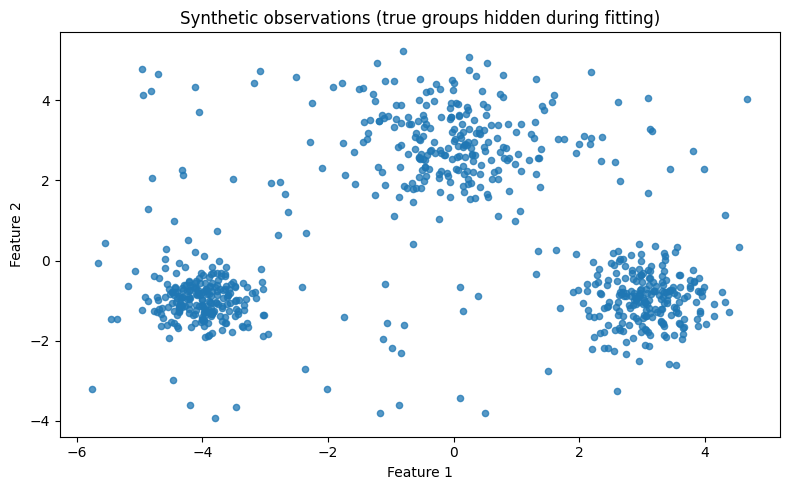

In [2]:
X_groups, y_groups = make_blobs(
    n_samples=650,
    centers=[(-4, -1), (0, 3), (3, -1)],
    cluster_std=[0.45, 0.85, 0.55],
    random_state=RANDOM_STATE,
)
rng = np.random.default_rng(RANDOM_STATE)
X_noise = rng.uniform(low=[-6, -4], high=[5, 5], size=(90, 2))
X = np.vstack([X_groups, X_noise])
y_true = np.concatenate([y_groups, np.full(len(X_noise), -1)])

plt.figure(figsize=(8, 5))
plt.scatter(X[:, 0], X[:, 1], s=20, alpha=0.75)
plt.title("Synthetic observations (true groups hidden during fitting)")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.tight_layout()
plt.show()

## 5. Fit HDBSCAN with Scikit-learn

The estimator's `labels_` contains the assigned cluster ID for each sample. Noise is represented by `-1`. The `probabilities_` array gives a membership-strength estimate for each observation; noise points have probability zero.

We set `min_samples` explicitly so that changing `min_cluster_size` does not silently change both controls at once.

In [16]:
hdbscan_model = HDBSCAN(
    min_cluster_size=25,
    min_samples=10,
    metric="euclidean",
    cluster_selection_method="eom",
    copy=False,
)

start_time = time.perf_counter()
labels_hdb = hdbscan_model.fit_predict(X)
fit_seconds = time.perf_counter() - start_time

probabilities = hdbscan_model.probabilities_
cluster_ids = sorted(label for label in np.unique(labels_hdb) if label != -1)
n_noise = int(np.sum(labels_hdb == -1))

print(f"Clusters found: {len(cluster_ids)}")
print(f"Noise points: {n_noise} / {len(X)} ({n_noise / len(X):.1%})")
print(f"Fit time: {fit_seconds:.4f} seconds")
print("Cluster labels:", np.unique(labels_hdb))

Clusters found: 3
Noise points: 60 / 740 (8.1%)
Fit time: 0.0187 seconds
Cluster labels: [-1  0  1  2]


In [17]:
summary = pd.DataFrame({
    "label": labels_hdb,
    "membership_probability": probabilities,
})
cluster_summary = (
    summary.groupby("label")
    .agg(
        n_samples=("label", "size"),
        mean_probability=("membership_probability", "mean"),
        median_probability=("membership_probability", "median"),
    )
    .sort_index()
)
display(cluster_summary)

,n_samples,mean_probability,median_probability
label,,,
-1,60,0.000000,0.000000
0,229,0.687959,0.769963
1,229,0.683077,0.727086
2,222,0.642394,0.595250


## 6. Visualize clusters and noise

Each cluster gets a color; noise observations are shown in light gray. Marker size and opacity do not encode certainty. The separate probability plot lets you inspect HDBSCAN's membership-strength estimates.

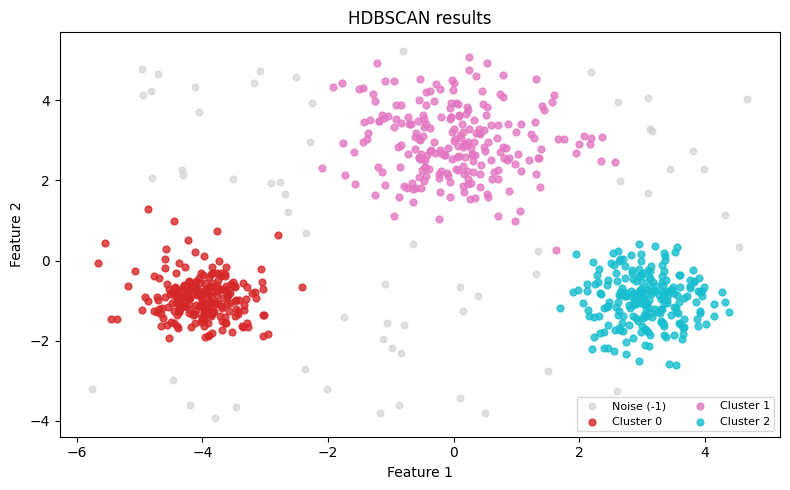

In [18]:
unique_labels = np.unique(labels_hdb)
colors = plt.cm.tab10(np.linspace(0, 1, max(len(unique_labels), 2)))

plt.figure(figsize=(8, 5))
for color, label in zip(colors, unique_labels):
    mask = labels_hdb == label
    if label == -1:
        plt.scatter(X[mask, 0], X[mask, 1], c="lightgray", s=22,
                    alpha=0.7, label="Noise (-1)")
    else:
        plt.scatter(X[mask, 0], X[mask, 1], color=color, s=24,
                    alpha=0.8, label=f"Cluster {label}")
plt.title("HDBSCAN results")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend(ncol=2, fontsize=8)
plt.tight_layout()
plt.show()

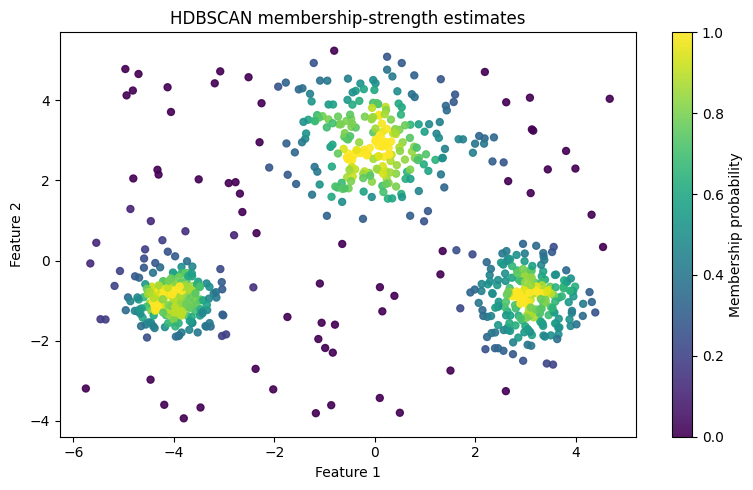

In [19]:
plt.figure(figsize=(8, 5))
scatter = plt.scatter(
    X[:, 0], X[:, 1],
    c=probabilities,
    cmap="viridis",
    vmin=0, vmax=1,
    s=25, alpha=0.9,
)
plt.colorbar(scatter, label="Membership probability")
plt.title("HDBSCAN membership-strength estimates")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.tight_layout()
plt.show()

**Interpretation prompt:** Which observations are marked as noise? Do low membership probabilities occur near the edges of clusters? A probability is a model-specific membership-strength estimate, not a calibrated probability that a label is objectively correct.

## 7. Parameter sensitivity

`min_cluster_size` controls the smallest group that may be retained. `min_samples` controls how conservatively density is interpreted. The table and plots below show how these choices change the number of clusters and the noise fraction.

This is a diagnostic experiment, not an automatic way to choose the “correct” parameters.

In [20]:
parameter_rows = []
min_cluster_sizes = [10, 20, 30, 45]
min_samples_values = [5, 10, 20]

for mcs in min_cluster_sizes:
    for ms in min_samples_values:
        model = HDBSCAN(
            min_cluster_size=mcs,
            min_samples=ms,
            cluster_selection_method="eom",
            copy=False
        )

        labels = model.fit_predict(X)
        clusters = set(labels) - {-1}

        parameter_rows.append({
            "min_cluster_size": mcs,
            "min_samples": ms,
            "n_clusters": len(clusters),
            "noise_fraction": np.mean(labels == -1),
        })

sensitivity = pd.DataFrame(parameter_rows)
display(sensitivity)

,min_cluster_size,min_samples,n_clusters,noise_fraction
0,10,5,3,0.071622
1,10,10,3,0.081081
2,10,20,3,0.093243
3,20,5,3,0.071622
4,20,10,3,0.081081
5,20,20,3,0.093243
6,30,5,3,0.071622
7,30,10,3,0.081081
8,30,20,3,0.093243
9,45,5,3,0.071622


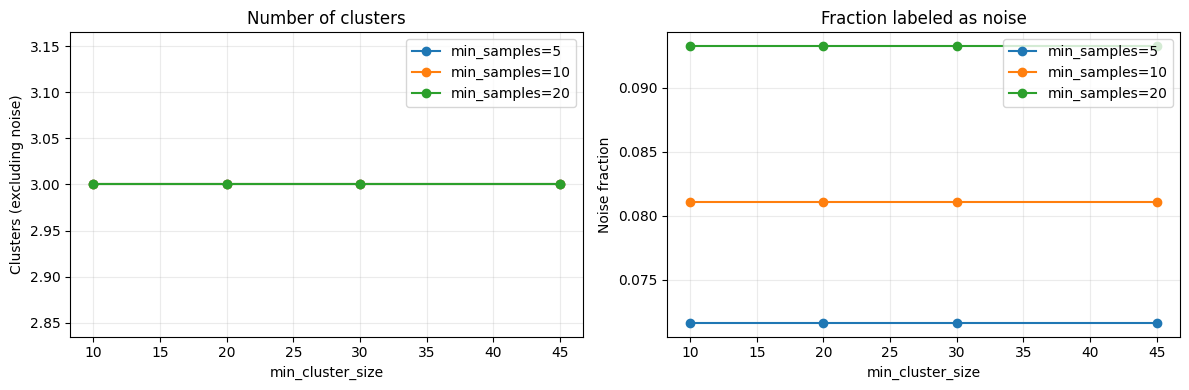

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ms, group in sensitivity.groupby("min_samples"):
    axes[0].plot(group["min_cluster_size"], group["n_clusters"],
                 marker="o", label=f"min_samples={ms}")
    axes[1].plot(group["min_cluster_size"], group["noise_fraction"],
                 marker="o", label=f"min_samples={ms}")
axes[0].set_title("Number of clusters")
axes[0].set_xlabel("min_cluster_size")
axes[0].set_ylabel("Clusters (excluding noise)")
axes[1].set_title("Fraction labeled as noise")
axes[1].set_xlabel("min_cluster_size")
axes[1].set_ylabel("Noise fraction")
for ax in axes:
    ax.legend()
    ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

**How to read this experiment**
- Larger `min_cluster_size` may discard small groups.
- Larger `min_samples` often makes the density criterion more conservative and can increase noise.
- A stable result across reasonable settings is useful evidence, but not proof that the clusters are meaningful.

## 8. Compare HDBSCAN, DBSCAN, and K-Means

These algorithms make different assumptions. K-Means needs a chosen number of clusters and tends to favor compact, roughly spherical groups. DBSCAN uses one global `eps` threshold. HDBSCAN explores density levels and selects stable clusters.

We standardize the features for a fairer distance-based comparison. `eps` for DBSCAN is illustrative and usually requires domain-specific tuning.

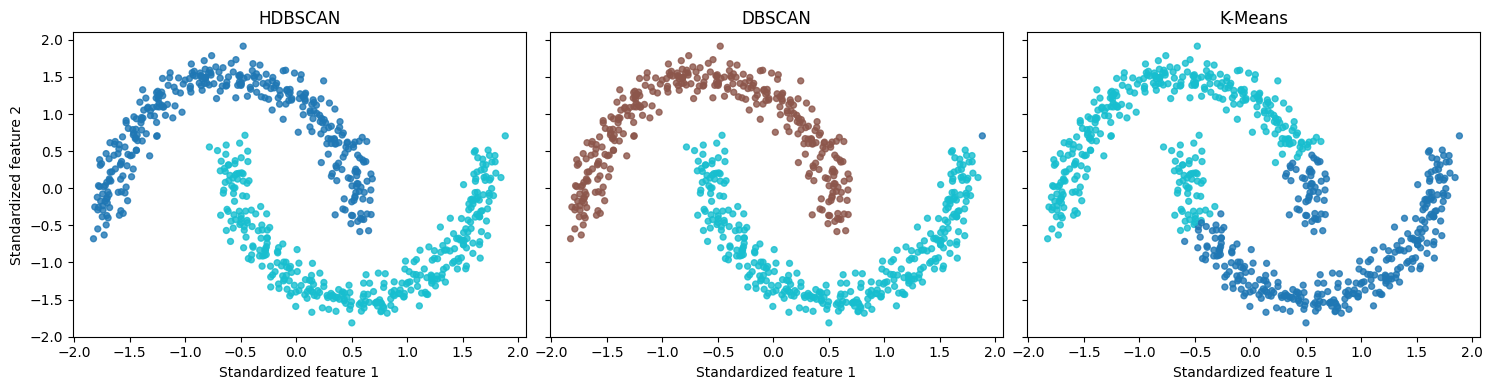

In [23]:

X_compare, y_compare = make_moons(
    n_samples=700, noise=0.07, random_state=RANDOM_STATE
)
X_compare = StandardScaler().fit_transform(X_compare)

labels_h = HDBSCAN(
    min_cluster_size=25,
    min_samples=10,
    copy=False,
).fit_predict(X_compare)

labels_d = DBSCAN(
    eps=0.22,
    min_samples=8,
).fit_predict(X_compare)

labels_k = KMeans(
    n_clusters=2,
    n_init=10,
    random_state=RANDOM_STATE,
).fit_predict(X_compare)

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharex=True, sharey=True)

for ax, labels, title in zip(
    axes,
    [labels_h, labels_d, labels_k],
    ["HDBSCAN", "DBSCAN", "K-Means"],
):
    ax.scatter(
        X_compare[:, 0],
        X_compare[:, 1],
        c=labels,
        cmap="tab10",
        s=18,
        alpha=0.8,
    )
    ax.set_title(title)
    ax.set_xlabel("Standardized feature 1")

axes[0].set_ylabel("Standardized feature 2")
plt.tight_layout()
plt.show()


## 9. Evaluation metrics

When reference labels are available, external metrics such as Adjusted Rand Index (ARI) and Normalized Mutual Information (NMI) can compare the clustering with those labels. For unsupervised work, reference labels are often unavailable; then use domain validation, stability analysis, and visualization.

For a transparent comparison here, we exclude noise points before calculating ARI/NMI and report the retained fraction separately. This convention makes the evaluation conditional on the observations HDBSCAN assigned to clusters, so it should not be compared blindly with scores computed on all points.

In [24]:
def evaluate_against_reference(y_reference, predicted):
    retained = predicted != -1
    if retained.sum() < 2 or len(np.unique(predicted[retained])) < 2:
        ari = np.nan
        nmi = np.nan
    else:
        ari = adjusted_rand_score(y_reference[retained], predicted[retained])
        nmi = normalized_mutual_info_score(y_reference[retained], predicted[retained])
    return {
        "n_clusters": len(set(predicted) - {-1}),
        "noise_fraction": float(np.mean(~retained)),
        "retained_fraction": float(np.mean(retained)),
        "ARI_on_retained": ari,
        "NMI_on_retained": nmi,
    }

# For the synthetic moons example, y_moons is unavailable by design.
# On the earlier blob dataset, the injected background noise has reference label -1.
# The next score is illustrative only: noise labels are not a true semantic class.
display(pd.DataFrame([
    evaluate_against_reference(y_true, labels_hdb)
]))

,n_clusters,noise_fraction,retained_fraction,ARI_on_retained,NMI_on_retained
0,3,0.081081,0.918919,0.91895,0.885587


## 10. Bioinformatics mini-project: synthetic gene expression

Gene-expression tables commonly have samples as rows and genes as columns. Features may have very different scales, so standardization is often a sensible starting point. We create a small synthetic dataset with three expression patterns and background variation.

This is a teaching example, **not biological evidence**. Real data require appropriate quality control, batch-effect assessment, feature selection, and validation.

In [25]:
rng = np.random.default_rng(RANDOM_STATE)
n_per_group = 80
n_genes = 40
n_groups = 3

expression_parts = []
group_truth = []
for group in range(n_groups):
    baseline = rng.normal(0, 0.5, size=n_genes)
    signature = np.zeros(n_genes)
    signature[group * 8:(group + 1) * 8] = 2.0
    samples = rng.normal(
        loc=baseline + signature,
        scale=0.8,
        size=(n_per_group, n_genes),
    )
    expression_parts.append(samples)
    group_truth.extend([group] * n_per_group)

expression = np.vstack(expression_parts)
gene_names = [f"Gene_{i+1:02d}" for i in range(n_genes)]
sample_names = [f"Sample_{i+1:03d}" for i in range(len(expression))]
expression_df = pd.DataFrame(expression, index=sample_names, columns=gene_names)

print("Expression matrix shape (samples × genes):", expression_df.shape)
display(expression_df.iloc[:5, :8])

Expression matrix shape (samples × genes): (240, 40)


,Gene_01,Gene_02,Gene_03,Gene_04,Gene_05,Gene_06,Gene_07,Gene_08
Sample_001,2.746962,1.914531,1.842818,2.656011,1.117831,1.523861,2.761063,2.020755
Sample_002,2.517779,0.950467,2.084783,2.164892,0.067811,1.738488,1.688398,1.851874
Sample_003,1.333561,1.623428,2.551223,3.557632,1.692571,1.634407,3.234563,0.890868
Sample_004,1.380265,0.899827,4.078001,1.813173,1.695274,0.626569,2.809179,2.149839
Sample_005,2.422418,2.605993,2.447694,2.985433,-0.615655,1.309936,1.389336,0.866828


In [27]:

# Standardize each gene across samples so that large-scale genes do not dominate.
scaler = StandardScaler()
X_expression = scaler.fit_transform(expression_df)

expression_model = HDBSCAN(
    min_cluster_size=18,
    min_samples=8,
    metric="euclidean",
    copy=False,
)

expression_labels = expression_model.fit_predict(X_expression)

print("Clusters found:", len(set(expression_labels) - {-1}))
print("Noise fraction:", f"{np.mean(expression_labels == -1):.1%}")

Clusters found: 3
Noise fraction: 0.8%


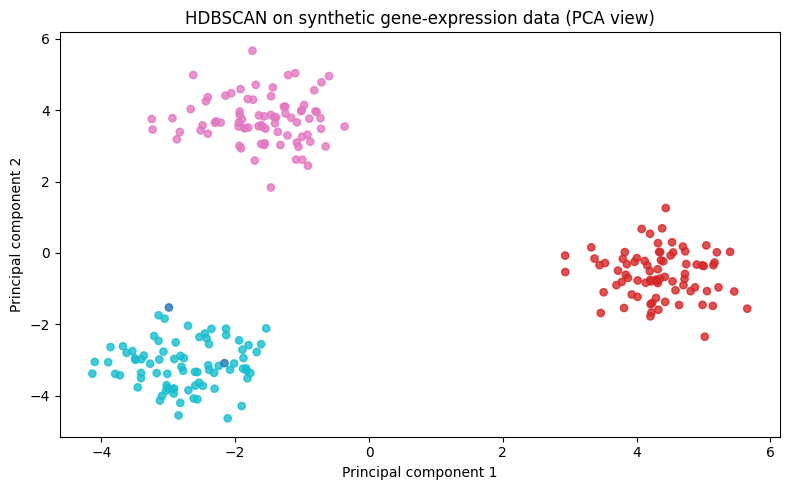

In [28]:
# PCA is used only to visualize the high-dimensional data in two dimensions.
X_pca = PCA(n_components=2, random_state=RANDOM_STATE).fit_transform(X_expression)

plt.figure(figsize=(8, 5))
scatter = plt.scatter(
    X_pca[:, 0], X_pca[:, 1],
    c=expression_labels, cmap="tab10",
    s=28, alpha=0.8,
)
plt.title("HDBSCAN on synthetic gene-expression data (PCA view)")
plt.xlabel("Principal component 1")
plt.ylabel("Principal component 2")
plt.tight_layout()
plt.show()

### Bioinformatics interpretation and safeguards

- A cluster is a pattern in the selected feature space, not automatically a disease subtype.
- PCA can distort distances and should be treated as a visualization, not as the clustering space in this example.
- Standardization is not universally correct; transformations and scaling depend on the data type and experimental design.
- If the data contain batches, technical artifacts can dominate clusters.
- Do not infer clinical meaning without independent validation and subject-matter expertise.

## 11. Computational complexity and practical guidance

Runtime and memory use depend on the number of observations, dimensionality, distance metric, and neighbor-search implementation. In practice:

- Scale or transform features thoughtfully before distance-based clustering.
- Remove irrelevant features and consider dimensionality reduction when justified.
- Try a small, interpretable grid of `min_cluster_size` and `min_samples`.
- Report the noise fraction as well as the number and sizes of clusters.
- Inspect whether conclusions persist across reasonable parameter settings.
- Treat `-1` as “not assigned to a cluster,” not necessarily as an error or an outlier in every domain.
- Scikit-learn's `HDBSCAN` API differs in some details from the third-party `hdbscan` package. Check the documentation for the installed version before copying parameters between them.

## 12. Exercises

1. Change `min_cluster_size` to 15, 35, and 60. How do the number and sizes of clusters change?
2. Keep `min_cluster_size` fixed and vary `min_samples` from 3 to 25. Describe the change in the noise fraction.
3. Replace the synthetic blob data with `make_moons`. Which method better follows the curved shapes, and why?
4. Standardize the data and compare results with the unscaled data. Why can feature scaling change density-based clustering?
5. Design a short results table containing the parameters, number of clusters, noise fraction, and a domain-specific validation measure.
6. Explain why a high silhouette score alone cannot prove that the clusters are scientifically meaningful.

## 13. Key takeaways

- HDBSCAN discovers density-based clusters across multiple density levels and selects stable groups.
- You do not need to specify the number of clusters in advance.
- Noise points receive label `-1`; report their fraction explicitly.
- `min_cluster_size` and `min_samples` control different aspects of the result.
- Membership probabilities and cluster stability are useful diagnostics, not guarantees of correctness.
- Good preprocessing, parameter sensitivity analysis, and domain validation matter as much as the estimator itself.